# Reposición de efectivo en cajeros automáticos

**La pregunta de negocio.** Un banco carga efectivo cada mañana en sus cajeros con un presupuesto limitado. ¿Cuánto debe cargar en cada uno para atender los retiros sin inmovilizar dinero de más?

> **Datos sintéticos.** El archivo es simulado. El ejercicio demuestra un método de decisión, y sus montos no representan a un banco real.

## Guía de lectura

**Qué vas a aprender**

- A separar dos problemas: lo que se **pronostica** y lo que se **decide**.
- A detectar qué información existe realmente al momento de decidir.
- A plantear una optimización con presupuesto, capacidad y costos.
- A evaluar políticas simulando el inventario día a día, sin mirar el futuro.
- A descubrir cuándo una regla simple alcanza a un optimizador.

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué decidimos y bajo qué supuestos? |
| 2. Calidad de datos y señal | ¿Se pueden anticipar los retiros? |
| 3. Pronóstico | ¿Qué modelo predice mejor? |
| 4. Políticas de reposición | ¿Qué alternativas compiten? |
| 5. Selección | ¿Cuál elegimos en validación? |
| 6. Prueba final | ¿Cuánto ahorra en días nuevos? |
| 7. Sensibilidad | ¿Qué supuestos cambian la decisión? |
| 8. Ficha | ¿Cómo se documenta? |
| 9. Limitaciones y monitoreo | ¿Qué falta para usarlo de verdad? |
| Conclusión | ¿Qué recomendamos? |

### Glosario rápido

| Término | Significado |
|---|---|
| **Política** | Regla que indica cuánto cargar cada día |
| **Faltante o quiebre** | Retiros que el cajero no pudo atender |
| **Saldo al cierre** | Efectivo que queda inmovilizado al final del día |
| **Servicio** | Porcentaje de los retiros que sí se atendieron |
| **Razón crítica** | Nivel de cobertura que equilibra el costo de faltar y el de sobrar |
| **Escenario** | Una posible demanda futura, tomada de días anteriores |
| **Optimización entera** | Búsqueda de la mejor decisión cuando las variables solo pueden tomar valores enteros |
| **Backtesting** | Simular una política sobre días pasados, usando solo lo que se conocía en cada momento |
| **MAE** | Error absoluto medio de un pronóstico |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Decisión** | Cuánto cargar en cada uno de 5 cajeros al inicio de cada día |
| **Restricciones** | Presupuesto diario compartido y capacidad por cajero |
| **Objetivo** | Minimizar el costo de faltantes, saldo inmovilizado y visitas |
| **Datos** | Retiros y depósitos diarios sintéticos de 2023 |
| **Fuera de alcance** | Diseño de rutas, denominación de billetes y seguridad del traslado |

**Qué falta en los datos.** El archivo no trae capacidad, saldo inicial ni costos. Los definimos como **supuestos** y en la sección 7 revisamos cuánto influyen.

**Un supuesto clave.** Los retiros registrados se tratan como demanda completa. En un cajero real, un retiro no atendido no siempre queda registrado.

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)

### Los parámetros del estudio

| Parámetro | Valor | Qué significa |
|---|---|---|
| `PROP_TRAIN`, `PROP_VALID` | 60 % y 15 % | Días para aprender y para elegir; el 25 % restante es la prueba final |
| `BLOQUE` | 1,000 | Unidad mínima de carga |
| `CAPACIDAD` | 30 bloques | Efectivo máximo por cajero |
| `SALDO_INICIAL` | 15 bloques | Efectivo en cada cajero al comenzar una simulación |
| `COSTO_FALTANTE` | 140 por bloque | Penaliza no atender un retiro |
| `COSTO_SALDO` | 12 por bloque | Penaliza el dinero que queda inmovilizado al cierre |
| `COSTO_VISITA` | 35 por cajero | Costo de abastecer un cajero |
| `PRESUPUESTO_PCT` | 100 % | Carga diaria máxima, respecto a la demanda media |
| `VENTANAS` | 8 a todo el historial | Cuántos días anteriores se usan como escenarios |
| `TOLERANCIA_COSTO` | 1 % | Entre políticas con menos de 1 % de diferencia, gana la más simple |

**La razón crítica.** Faltar cuesta 140 y sobrar cuesta 12. La cobertura ideal es $\frac{140}{140 + 12} = 92.1\,\%$: conviene llevar efectivo suficiente para cubrir cerca del 92 % de los días. Es la idea clásica del problema del vendedor de periódicos.

> **Criterio.** Los costos son valores ilustrativos. Un resultado depende de ellos, y por eso se analizan con distintos valores.

In [2]:
# Partición temporal
PROP_TRAIN, PROP_VALID = 0.60, 0.15

# Supuestos operativos: el archivo no los trae
BLOQUE = 1000             # unidad mínima de carga
CAPACIDAD = 30            # bloques por cajero
SALDO_INICIAL = 15        # bloques por cajero al iniciar una simulación
COSTO_FALTANTE = 140      # por bloque no atendido
COSTO_SALDO = 12          # por bloque que queda al cierre
COSTO_VISITA = 35         # por cajero recargado
PRESUPUESTO_PCT = 1.00    # carga diaria máxima como proporción de la demanda media

# Selección de la política
VENTANAS = [8, 30, 60, 120, None]
TOLERANCIA_COSTO = 0.01   # diferencia relativa por debajo de la cual preferimos lo más simple

# Remuestreo
SEMILLA, N_BOOTSTRAP, BLOQUE_DIAS = 7, 2000, 7

AZUL, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})

def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

## 2. Calidad de datos y señal

Antes de optimizar hay que preguntarse si los retiros se pueden anticipar. También hay que distinguir qué variables se conocen **antes** de decidir.

**Eta²** indica qué parte de la variación de los retiros se explica con cada variable.

,Resultado,Tratamiento
Control,,
Fechas consecutivas y 5 cajeros por día,Correcto,Panel completo
Retiros negativos,0,Ninguno
Cajeros cuya ubicación cambia entre días,5,Inconsistente: no se usa para decidir
Días con feriado,3,Muy pocos para modelarlos aparte


Withdrawals                      Deposits                     
              mean     std   min    max     mean     std   min    max
ATM_ID                                                               
ATM_1      17170.0  4176.0  5464  24882   9002.0  3168.0  3072  14996
ATM_2      17151.0  4212.0  5138  24968   9250.0  3095.0  3021  14973
ATM_3      17316.0  4050.0  5000  24986   9129.0  3119.0  3001  14909
ATM_4      16457.0  4419.0  5000  24957   8591.0  3065.0  3077  14947
ATM_5      16857.0  4003.0  5257  24911   8809.0  3204.0  3143  14956

,Variación explicada (eta²),¿Se conoce al decidir?
Cajero,0.005,Sí
Día de la semana,0.096,Sí
Laborable o no,0.102,Sí
Feriado,0.014,Sí
Clima,0.091,No: es del mismo día
Ubicación,0.325,No: cambia sin explicación


Autocorrelación de un día por cajero: [np.float64(-0.044), np.float64(0.145), np.float64(0.033), np.float64(0.02), np.float64(0.073)]
Demanda total diaria: media 84,952 | desviación 11,243


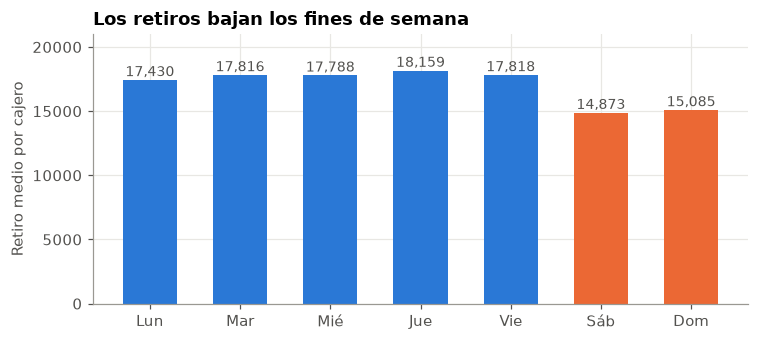

In [3]:
candidatas = [Path('data/synthetic_atm_cash_data.csv'), Path('synthetic_atm_cash_data.csv'),
              Path.home() / 'Downloads' / 'synthetic_atm_cash_data.csv']
ruta = next(p for p in candidatas if p.is_file())
df = pd.read_csv(ruta, parse_dates=['Date']).sort_values(['Date', 'ATM_ID']).reset_index(drop=True)
assert df.shape == (1825, 8), 'El archivo no coincide con la versión esperada'
assert not df.duplicated(['Date', 'ATM_ID']).any() and df.isna().sum().sum() == 0
assert (df.groupby('Date').size() == 5).all() and (df['DayOfWeek'] == df['Date'].dt.weekday).all()

DIAS = np.sort(df['Date'].unique())
ATMS = sorted(df['ATM_ID'].unique())
assert (pd.Timestamp(DIAS[-1]) - pd.Timestamp(DIAS[0])).days + 1 == len(DIAS)

controles = pd.DataFrame([
    ('Fechas consecutivas y 5 cajeros por día', 'Correcto', 'Panel completo'),
    ('Retiros negativos', int((df['Withdrawals'] < 0).sum()), 'Ninguno'),
    ('Cajeros cuya ubicación cambia entre días', int((df.groupby('ATM_ID')['Location'].nunique() > 1).sum()), 'Inconsistente: no se usa para decidir'),
    ('Días con feriado', int(df.loc[df['IsHoliday'] == 1, 'Date'].nunique()), 'Muy pocos para modelarlos aparte'),
], columns=['Control', 'Resultado', 'Tratamiento']).set_index('Control')
display(controles)
display(df.groupby('ATM_ID')[['Withdrawals', 'Deposits']].agg(['mean', 'std', 'min', 'max']).round(0))

def eta2(columna):
    g = df.groupby(columna)['Withdrawals']
    return 1 - ((df['Withdrawals'] - g.transform('mean')) ** 2).sum() / ((df['Withdrawals'] - df['Withdrawals'].mean()) ** 2).sum()

panel = df.pivot(index='Date', columns='ATM_ID', values='Withdrawals')
df['tipo_dia'] = np.where((df['DayOfWeek'] >= 5) | (df['IsHoliday'] == 1), 'Fin de semana o feriado', 'Laborable')
senal = pd.DataFrame({
    'Variación explicada (eta²)': {v: round(eta2(c_), 3) for v, c_ in [('Cajero', 'ATM_ID'), ('Día de la semana', 'DayOfWeek'), ('Laborable o no', 'tipo_dia'), ('Feriado', 'IsHoliday'), ('Clima', 'WeatherImpact'), ('Ubicación', 'Location')]},
    '¿Se conoce al decidir?': {'Cajero': 'Sí', 'Día de la semana': 'Sí', 'Laborable o no': 'Sí', 'Feriado': 'Sí', 'Clima': 'No: es del mismo día', 'Ubicación': 'No: cambia sin explicación'}})
display(senal)
print('Autocorrelación de un día por cajero:', [round(panel[a].autocorr(1), 3) for a in ATMS])
print(f'Demanda total diaria: media {panel.sum(1).mean():,.0f} | desviación {panel.sum(1).std():,.0f}')

por_dia = df.groupby('DayOfWeek')['Withdrawals'].mean()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'], por_dia.values, color=[AZUL] * 5 + [NARANJA] * 2, width=0.6)
ax.set(ylabel='Retiro medio por cajero', title='Los retiros bajan los fines de semana', ylim=(0, 21000))
for i, v in enumerate(por_dia.values):
    ax.text(i, v + 300, f'{v:,.0f}', ha='center', color=TINTA, fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.**

- **El panel está completo:** 365 días y 5 cajeros, sin faltantes.
- **`Location` es inconsistente.** Los 5 cajeros aparecen como urbanos algunos días y rurales otros, algo imposible para un cajero fijo. Explica el 32.5 % de la variación, pero no se puede usar para decidir.
- **El clima no se conoce al decidir.** Es un dato del mismo día, y usarlo sería fuga de información.
- **La señal disponible es poca.** Saber si el día es laborable explica cerca del 10 %, y los cajeros casi no se diferencian entre sí (0.5 %).
- **Casi no hay memoria.** Lo que ocurrió ayer casi no dice nada de hoy.

**Consecuencia:** gran parte de la demanda es ruido. Un método que reaccione mucho a pocos días recientes va a perseguir ese ruido.

## 3. Pronóstico

Dividimos el tiempo en tres tramos, sin mezclarlos. Comparamos pronósticos en el periodo de validación, desde una media global hasta un modelo de boosting.

La última fila usa ubicación y clima, y **no estaría disponible en la práctica**. Sirve para medir cuánta información nos falta.

In [4]:
n = len(DIAS)
FIN_TRAIN, FIN_VALID = int(PROP_TRAIN * n), int((PROP_TRAIN + PROP_VALID) * n)
DEMANDA = panel[ATMS].to_numpy() / BLOQUE
DEPOSITOS = df.pivot(index='Date', columns='ATM_ID', values='Deposits')[ATMS].to_numpy() / BLOQUE
tipo = df.drop_duplicates('Date').set_index('Date')['tipo_dia'].reindex(DIAS).to_numpy()
ES_LABORABLE = tipo == 'Laborable'
PRESUPUESTO = int(round(PRESUPUESTO_PCT * DEMANDA[:FIN_TRAIN].sum(1).mean()))

print(f'Entrenamiento: {pd.Timestamp(DIAS[0]).date()} a {pd.Timestamp(DIAS[FIN_TRAIN - 1]).date()} ({FIN_TRAIN} días)')
print(f'Validación: {pd.Timestamp(DIAS[FIN_TRAIN]).date()} a {pd.Timestamp(DIAS[FIN_VALID - 1]).date()} ({FIN_VALID - FIN_TRAIN} días)')
print(f'Prueba: {pd.Timestamp(DIAS[FIN_VALID]).date()} a {pd.Timestamp(DIAS[-1]).date()} ({n - FIN_VALID} días)')
print(f'Presupuesto diario base: {PRESUPUESTO * BLOQUE:,} | Capacidad total: {5 * CAPACIDAD * BLOQUE:,}')

datos = df[df['Date'] < DIAS[FIN_VALID]].copy()
datos['finde'] = (datos['tipo_dia'] != 'Laborable').astype(int)
tr_ = datos['Date'] < DIAS[FIN_TRAIN]
va_ = ~tr_
y_tr, y_va = datos.loc[tr_, 'Withdrawals'], datos.loc[va_, 'Withdrawals']
tau = COSTO_FALTANTE / (COSTO_FALTANTE + COSTO_SALDO)

def resultado(p_):
    e = y_va.to_numpy() - np.asarray(p_)
    return {'MAE': round(np.abs(e).mean()), 'Sesgo': round(e.mean())}

X_cal = pd.get_dummies(datos[['ATM_ID']], dtype=float).assign(finde=datos['finde'].astype(float), feriado=datos['IsHoliday'].astype(float))
X_inf = X_cal.assign(rural=(datos['Location'] == 'Rural').astype(float), clima=datos['WeatherImpact'].astype(float))
ult8 = []
for d_ in datos.loc[va_, 'Date'].unique():
    previos = [x for x in DIAS if x < d_ and pd.Timestamp(x).weekday() == pd.Timestamp(d_).weekday()][-8:]
    ult8.append(panel.loc[previos, ATMS].mean().to_numpy())
pron = {
    'Media global': np.full(va_.sum(), y_tr.mean()),
    'Media por cajero': datos.loc[va_, 'ATM_ID'].map(datos[tr_].groupby('ATM_ID')['Withdrawals'].mean()).to_numpy(),
    'Últimos 8 días iguales': np.ravel(ult8),
    'Media por tipo de día': datos.loc[va_, 'finde'].map(datos[tr_].groupby('finde')['Withdrawals'].mean()).to_numpy(),
    'Regresión de calendario': LinearRegression().fit(X_cal[tr_], y_tr).predict(X_cal[va_]),
    'Boosting de calendario': GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEMILLA).fit(X_cal[tr_], y_tr).predict(X_cal[va_]),
    'Regresión con ubicación y clima (no disponible)': LinearRegression().fit(X_inf[tr_], y_tr).predict(X_inf[va_]),
}
pd.DataFrame({k_: resultado(v_) for k_, v_ in pron.items()}).T.sort_values('MAE')

Entrenamiento: 2023-01-01 a 2023-08-07 (219 días)
Validación: 2023-08-08 a 2023-09-30 (54 días)
Prueba: 2023-10-01 a 2023-12-31 (92 días)
Presupuesto diario base: 85,000 | Capacidad total: 150,000


,MAE,Sesgo
Regresión con ubicación y clima (no disponible),2467,94
Regresión de calendario,3314,43
Boosting de calendario,3317,46
Media por tipo de día,3325,70
Media global,3355,115
Media por cajero,3365,115
Últimos 8 días iguales,3452,25


**Lectura.** Los modelos con calendario son los mejores entre los utilizables (MAE de 3,314), aunque apenas superan a una media global (3,355). Boosting no aporta nada adicional, y mirar solo los últimos 8 días iguales es el peor (3,452), porque usa muy pocos datos. Conocer ubicación y clima reduciría el error a 2,467, y eso muestra cuánto valor tendría la información que no tenemos.

## 4. Políticas de reposición

**Cómo funciona la simulación.** Cada mañana se decide la carga, ocurren los retiros, y lo que queda pasa al día siguiente. Por eso una decisión de hoy afecta a mañana.

**Ejemplo de costo.** Un cajero recargado tiene 20 bloques. Si los retiros son 23, faltan 3 bloques: $3 \times 140 + 35 = 455$. Si son 17, sobran 3: $3 \times 12 + 35 = 71$. Faltar es mucho más caro que sobrar.

**Las políticas**

| Política | Regla | Complejidad |
|---|---|---|
| **Reparto uniforme** | Divide el presupuesto por igual | Mínima |
| **Nivel fijo** | Lleva cada cajero a un nivel objetivo constante | Baja |
| **Nivel por tipo de día** | El objetivo cambia entre laborables y fines de semana | Media |
| **Optimización entera** | Resuelve un problema matemático cada día | Alta |

Para las políticas con nivel, el objetivo es el cuantil 92.1 de la demanda. Si el total supera el presupuesto, se recorta la carga mayor.

**La optimización diaria.** Con $q_a$ como la carga del cajero $a$ y $z_a$ como la decisión de visitarlo, sobre los escenarios $w$:

$$\min \sum_a c_v z_a + \frac{1}{|W|} \sum_{a,w} \left( c_f\, f_{a,w} + c_s\, s_{a,w} \right)$$

sujeto a que la carga total no supere el presupuesto y cada cajero no supere su capacidad. Aquí $f$ es el faltante y $s$ el saldo al cierre en cada escenario.

**Comprobación.** Un error en la formulación daría una respuesta incorrecta sin avisar. Por eso comparamos el resultado con otro método exacto, la programación dinámica, sobre casos al azar.

In [5]:
@dataclass(frozen=True)
class Escenario:
    presupuesto: int = PRESUPUESTO
    capacidad: int = CAPACIDAD
    faltante: float = COSTO_FALTANTE
    saldo: float = COSTO_SALDO
    visita: float = COSTO_VISITA
    reciclaje: float = 0.0

BASE = Escenario()

def resolver(inventario, esc, cfg):
    """Elige la carga de cada cajero minimizando el costo medio en los escenarios."""
    m, a = esc.shape[0], esc.shape[1]
    nq, nz = a, a
    total = nq + nz + 2 * a * m
    costo = np.zeros(total)
    costo[nq:nq + nz] = cfg.visita
    costo[nq + nz:nq + nz + a * m] = cfg.faltante / m
    costo[nq + nz + a * m:] = cfg.saldo / m
    A = lil_matrix((2 * a * m + a + 1, total))
    li, ls = [], []
    fila = 0
    for j in range(a):
        for w in range(m):
            A[fila, j] = 1; A[fila, nq + nz + j * m + w] = 1
            li.append(esc[w, j] - inventario[j]); ls.append(np.inf); fila += 1
            A[fila, j] = -1; A[fila, nq + nz + a * m + j * m + w] = 1
            li.append(inventario[j] - esc[w, j]); ls.append(np.inf); fila += 1
    maximos = np.maximum(cfg.capacidad - inventario, 0)
    for j in range(a):
        A[fila, j] = 1; A[fila, nq + j] = -max(maximos[j], 0)
        li.append(-np.inf); ls.append(0); fila += 1
    A[fila, :nq] = 1
    li.append(0); ls.append(cfg.presupuesto)
    tipos = np.r_[np.ones(nq + nz), np.zeros(2 * a * m)]
    cota_sup = np.r_[np.floor(maximos), np.ones(nz), np.full(2 * a * m, np.inf)]
    r = milp(costo, constraints=LinearConstraint(A.tocsr(), li, ls), integrality=tipos, bounds=Bounds(np.zeros(total), cota_sup), options={'mip_rel_gap': 1e-6})
    assert r.success, r.message
    return np.round(r.x[:nq]).astype(int)

def escenarios(t, ventana):
    """Días anteriores del mismo tipo: no usa información del día de la decisión."""
    previos = np.flatnonzero(ES_LABORABLE[:t] == ES_LABORABLE[t])
    return DEMANDA[previos if ventana is None else previos[-ventana:]]

def ajustar_a_presupuesto(q, inventario, cfg):
    q = np.minimum(np.maximum(np.round(q), 0), np.maximum(cfg.capacidad - inventario, 0)).astype(int)
    exceso = q.sum() - cfg.presupuesto
    while exceso > 0:
        q[np.argmax(q)] -= 1
        exceso -= 1
    return q

def p_uniforme(t, inv, cfg):
    return ajustar_a_presupuesto(np.full(5, np.ceil(cfg.presupuesto / 5)), inv, cfg)

def nivel(t, ventana):
    return np.quantile(escenarios(t, ventana), tau, axis=0)

def p_nivel_fijo(t, inv, cfg):
    return ajustar_a_presupuesto(np.quantile(DEMANDA[:FIN_TRAIN], tau, axis=0) - inv, inv, cfg)

def p_nivel_tipo(ventana):
    return lambda t, inv, cfg: ajustar_a_presupuesto(nivel(t, ventana) - inv, inv, cfg)

def p_optimo(ventana):
    return lambda t, inv, cfg: resolver(inv, escenarios(t, ventana), cfg)

def plan_perfecto(inicio, fin, cfg, saldo0=SALDO_INICIAL):
    """Plan de referencia si se conociera toda la demanda futura; no es alcanzable en la práctica."""
    T_, a = fin - inicio, 5
    nv = 4 * T_ * a
    q_, z_, f_, e_ = (lambda t, j: t * a + j), (lambda t, j: T_ * a + t * a + j), (lambda t, j: 2 * T_ * a + t * a + j), (lambda t, j: 3 * T_ * a + t * a + j)
    costo = np.r_[np.zeros(T_ * a), np.full(T_ * a, cfg.visita), np.full(T_ * a, cfg.faltante), np.full(T_ * a, cfg.saldo)]
    A = lil_matrix((2 * T_ * a + T_ * a + T_, nv))
    li, ls, fila = [], [], 0
    for t_ in range(T_):
        for j in range(a):
            # saldo al cierre = saldo previo + carga + faltante - demanda
            A[fila, e_(t_, j)] = 1; A[fila, q_(t_, j)] = -1; A[fila, f_(t_, j)] = -1
            if t_ > 0:
                A[fila, e_(t_ - 1, j)] = -1
            previo = saldo0 if t_ == 0 else 0
            li.append(previo - DEMANDA[inicio + t_, j]); ls.append(previo - DEMANDA[inicio + t_, j]); fila += 1
            A[fila, q_(t_, j)] = 1
            if t_ > 0:
                A[fila, e_(t_ - 1, j)] = 1
            li.append(-np.inf); ls.append(cfg.capacidad - (saldo0 if t_ == 0 else 0)); fila += 1
            A[fila, q_(t_, j)] = 1; A[fila, z_(t_, j)] = -cfg.capacidad
            li.append(-np.inf); ls.append(0); fila += 1
        for j in range(a):
            A[fila, q_(t_, j)] = 1
        li.append(0); ls.append(cfg.presupuesto); fila += 1
    integ = np.zeros(nv)  # versión lineal: visita diaria a todos los cajeros y cargas continuas
    sup = np.r_[np.full(T_ * a, cfg.capacidad), np.ones(T_ * a), np.full(2 * T_ * a, np.inf)]
    r = milp(costo, constraints=LinearConstraint(A.tocsr(), li, ls), integrality=integ, bounds=Bounds(np.r_[np.zeros(T_ * a), np.ones(T_ * a), np.zeros(2 * T_ * a)], sup))
    assert r.success, r.message
    return r.x[:T_ * a].reshape(T_, a)

def simular(politica, inicio, fin, cfg=BASE, saldo0=SALDO_INICIAL):
    inv = np.full(5, float(saldo0))
    filas = []
    for t in range(inicio, fin):
        q = np.asarray(politica(t, inv, cfg))
        assert (q >= 0).all() and q.sum() <= cfg.presupuesto + 1e-9 and ((inv + q) <= cfg.capacidad + 1e-9).all()
        disponible = inv + q
        demanda = DEMANDA[t]
        falta = np.maximum(demanda - disponible, 0)
        cierre = np.maximum(disponible - demanda, 0)
        visitas = (q > 0).sum()
        filas.append({'costo': cfg.faltante * falta.sum() + cfg.saldo * cierre.sum() + cfg.visita * visitas, 'faltante': falta.sum(),
                      'demanda': demanda.sum(), 'cierre': cierre.sum(), 'visitas': visitas, 'carga': q.sum(), 'quiebres': (falta > 1e-9).sum()})
        inv = np.minimum(cierre + cfg.reciclaje * DEPOSITOS[t], cfg.capacidad)
    return pd.DataFrame(filas)

def resumen(r):
    return {'Costo diario': round(r['costo'].mean()), 'Servicio': pct(1 - r['faltante'].sum() / r['demanda'].sum()), 'Cajeros-día con quiebre': pct(r['quiebres'].sum() / (5 * len(r))),
            'Saldo al cierre': round(r['cierre'].mean() * BLOQUE), 'Visitas por día': round(r['visitas'].mean(), 2), 'Carga diaria': round(r['carga'].mean() * BLOQUE)}

# Comprobación independiente: programación dinámica frente al optimizador entero
def exacto(inventario, esc, cfg):
    estados = {0: 0.0}
    for j in range(5):
        tope = int(max(cfg.capacidad - inventario[j], 0))
        costos = [cfg.visita * (q > 0) + np.mean(cfg.faltante * np.maximum(esc[:, j] - inventario[j] - q, 0) + cfg.saldo * np.maximum(inventario[j] + q - esc[:, j], 0)) for q in range(tope + 1)]
        nuevos = {}
        for usado, v in estados.items():
            for q, c_ in enumerate(costos[:cfg.presupuesto - usado + 1]):
                if usado + q not in nuevos or v + c_ < nuevos[usado + q]:
                    nuevos[usado + q] = v + c_
        estados = nuevos
    return min(estados.values())

def valor(q, inventario, esc, cfg):
    return sum(cfg.visita * (q[j] > 0) + np.mean(cfg.faltante * np.maximum(esc[:, j] - inventario[j] - q[j], 0) + cfg.saldo * np.maximum(inventario[j] + q[j] - esc[:, j], 0)) for j in range(5))

rng = np.random.default_rng(SEMILLA)
dif = []
for t in rng.choice(np.arange(FIN_TRAIN, FIN_VALID), 10, replace=False):
    inv_ = rng.integers(0, CAPACIDAD, 5).astype(float)
    esc_ = escenarios(int(t), 30)
    dif.append(abs(valor(resolver(inv_, esc_, BASE), inv_, esc_, BASE) - exacto(inv_, esc_, BASE)))
print(f'Mayor diferencia entre optimizador y solución exacta en 10 pruebas: {max(dif):.4f}')

Mayor diferencia entre optimizador y solución exacta en 10 pruebas: 0.0000


**Lectura.** La diferencia máxima entre ambos métodos es 0.0000: el optimizador resuelve correctamente el problema planteado.

## 5. Selección en validación

Primero elegimos cuántos días anteriores usar como escenarios. Después comparamos las políticas con una regla fijada de antemano: **entre las políticas a menos de 1 % de la mejor, gana la más simple**.

La validación no se usa para la prueba final, y evita ajustar la decisión a los días con los que después se evaluará.

In [6]:
filas = []
for v in VENTANAS:
    etiqueta = 'Todo el historial' if v is None else f'Últimos {v} días'
    filas.append({'Ventana': etiqueta, 'Política': 'Nivel por tipo de día', 'Costo diario': simular(p_nivel_tipo(v), FIN_TRAIN, FIN_VALID)['costo'].mean(), 'ventana': v})
    filas.append({'Ventana': etiqueta, 'Política': 'Optimización entera', 'Costo diario': simular(p_optimo(v), FIN_TRAIN, FIN_VALID)['costo'].mean(), 'ventana': v})
ajuste = pd.DataFrame(filas)
display(ajuste.pivot(index='Ventana', columns='Política', values='Costo diario').loc[['Últimos 8 días', 'Últimos 30 días', 'Últimos 60 días', 'Últimos 120 días', 'Todo el historial']].round(1))
V_NIVEL = ajuste[ajuste['Política'] == 'Nivel por tipo de día'].sort_values('Costo diario').iloc[0]['ventana']
V_OPT = ajuste[ajuste['Política'] == 'Optimización entera'].sort_values('Costo diario').iloc[0]['ventana']
V_NIVEL = None if pd.isna(V_NIVEL) else int(V_NIVEL)
V_OPT = None if pd.isna(V_OPT) else int(V_OPT)
print(f'Ventana elegida. Nivel por tipo de día: {V_NIVEL} | Optimización entera: {V_OPT}')

POLITICAS = {'Reparto uniforme': p_uniforme, 'Nivel fijo': p_nivel_fijo, 'Nivel por tipo de día': p_nivel_tipo(V_NIVEL), 'Optimización entera': p_optimo(V_OPT)}
COMPLEJIDAD = {'Reparto uniforme': 0, 'Nivel fijo': 1, 'Nivel por tipo de día': 2, 'Optimización entera': 3}
val = {k: simular(f, FIN_TRAIN, FIN_VALID) for k, f in POLITICAS.items()}
tabla_val = pd.DataFrame({k: resumen(r) for k, r in val.items()}).T
display(tabla_val)
costos = {k: r['costo'].mean() for k, r in val.items()}
mejor_costo = min(costos.values())
ELEGIDA = min([k for k, v in costos.items() if v <= mejor_costo * (1 + TOLERANCIA_COSTO)], key=COMPLEJIDAD.get)
print(f'Mejor costo en validación: {min(costos, key=costos.get)} ({mejor_costo:,.0f})')
print(f'Política elegida con la regla de parsimonia: {ELEGIDA}')

Política,Nivel por tipo de día,Optimización entera
Ventana,,
Últimos 8 días,811.5,797.9
Últimos 30 días,779.3,727.9
Últimos 60 días,760.2,717.7
Últimos 120 días,759.3,706.7
Todo el historial,760.1,709.5


Ventana elegida. Nivel por tipo de día: 120 | Optimización entera: 120


,Costo diario,Servicio,Cajeros-día con quiebre,Saldo al cierre,Visitas por día,Carga diaria
Reparto uniforme,905,97.2 %,17.8 %,32819,5.0,82037
Nivel fijo,706,97.8 %,20.4 %,22302,5.0,82444
Nivel por tipo de día,759,97.2 %,24.8 %,20466,5.0,81926
Optimización entera,707,97.5 %,24.1 %,19700,5.0,82296


Mejor costo en validación: Nivel fijo (706)
Política elegida con la regla de parsimonia: Nivel fijo


**Lectura.**

- **Más historia ayuda.** Con los últimos 8 días, la optimización cuesta 798. Con 120 días, baja a 707. Pocos escenarios hacen que el optimizador persiga ruido.
- **El nivel fijo gana la selección** (706), prácticamente igual a la optimización entera (707).
- **Distinguir fines de semana empeora el resultado** (759). Una explicación probable: con un presupuesto ajustado, bajar el nivel el fin de semana deja menos reserva para el lunes.

## 6. Prueba final

Evaluamos cada política en los últimos 92 días, enfrentando exactamente los mismos retiros.

**Una referencia inalcanzable.** "Información perfecta del periodo" resuelve el plan conociendo toda la demanda futura, con cargas continuas y visitando todos los cajeros a diario. Muestra cuánto ahorro sería posible en teoría.

**Bootstrap por bloques.** Los costos de días cercanos pueden estar relacionados, porque el inventario se arrastra. Por eso remuestreamos semanas completas y no días sueltos.

,Costo diario,Servicio,Cajeros-día con quiebre,Saldo al cierre,Visitas por día,Carga diaria
Reparto uniforme,935,97.0 %,18.9 %,33165,5.0,82261
Nivel fijo,800,97.0 %,19.8 %,22349,5.0,82098
Nivel por tipo de día,824,96.6 %,22.0 %,20400,5.0,81641
Optimización entera,797,96.8 %,24.3 %,19741,5.0,81772
Información perfecta del periodo,490,98.3 %,3.7 %,9888,4.9,82745


,Diferencia de costo diario,IC 95 %,Probabilidad de ahorro,Ahorro relativo
Elegida menos,,,,
Reparto uniforme,-135,-212 a -26,99.5 %,14.4 %
Nivel por tipo de día,-24,-67 a +4,95.5 %,2.9 %
Optimización entera,2,-51 a +47,52.0 %,-0.3 %


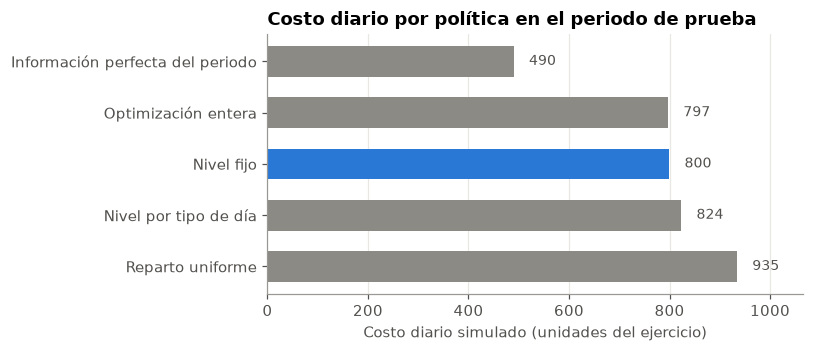

In [7]:
pru = {k: simular(f, FIN_VALID, n) for k, f in POLITICAS.items()}
PLAN = plan_perfecto(FIN_VALID, n, BASE)
pru['Información perfecta del periodo'] = simular(lambda t, inv, cfg: PLAN[t - FIN_VALID], FIN_VALID, n)
display(pd.DataFrame({k: resumen(r) for k, r in pru.items()}).T)

rng = np.random.default_rng(SEMILLA)
dias_test = n - FIN_VALID
inicios = np.arange(0, dias_test - BLOQUE_DIAS + 1)
def bootstrap_dif(a_, b_):
    d_ = a_ - b_
    medias = np.empty(N_BOOTSTRAP)
    for i_ in range(N_BOOTSTRAP):
        s = rng.choice(inicios, int(np.ceil(dias_test / BLOQUE_DIAS)))
        medias[i_] = np.concatenate([d_[x:x + BLOQUE_DIAS] for x in s])[:dias_test].mean()
    return d_.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5), (medias < 0).mean()

filas = []
for k in [x for x in POLITICAS if x != ELEGIDA]:
    m_, li, ls, prob = bootstrap_dif(pru[ELEGIDA]['costo'].to_numpy(), pru[k]['costo'].to_numpy())
    filas.append({'Elegida menos': k, 'Diferencia de costo diario': round(m_), 'IC 95 %': f'{li:+,.0f} a {ls:+,.0f}', 'Probabilidad de ahorro': pct(prob), 'Ahorro relativo': pct(-m_ / pru[k]['costo'].mean())})
display(pd.DataFrame(filas).set_index('Elegida menos'))

ord_ = pd.Series({k: r['costo'].mean() for k, r in pru.items()}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.barh(ord_.index, ord_.values, color=[AZUL if x == ELEGIDA else GRIS for x in ord_.index], height=0.6)
for i, v in enumerate(ord_.values):
    ax.text(v + 30, i, f'{v:,.0f}', va='center', color=TINTA, fontsize=9)
ax.set(xlabel='Costo diario simulado (unidades del ejercicio)', title='Costo diario por política en el periodo de prueba', xlim=(0, ord_.max() * 1.14))
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Lectura.**

- **El nivel fijo ahorra 135 por día frente al reparto uniforme (14.4 %)**, con un intervalo de −212 a −26. Atiende el mismo 97.0 % de los retiros con unos 10,800 menos de efectivo inmovilizado.
- **Empata con la optimización entera.** La diferencia es de 2, con un intervalo de −51 a +47. La complejidad adicional no se justifica en estos datos.
- **Información perfecta costaría 490.** La brecha frente a 800 es el precio de la incertidumbre, que ninguna política puede eliminar del todo con esta información.
- **El servicio de 97 % no significa ausencia de quiebres:** el 19.8 % de los cajeros-día tuvo algún faltante, generalmente pequeño.

## 7. Sensibilidad

### ¿Y si cambia el presupuesto?

El nivel objetivo se mantiene fijo con el costo base, para ver qué pasa cuando cambia el entorno y la política no se ajusta.

,Elegida,Uniforme,Optimización entera,Ahorro frente a uniforme,Servicio de la elegida
Presupuesto / demanda media,,,,,
80 %,2591,2572,2579,-0.7 %,80.3 %
90 %,1577,1607,1555,1.9 %,89.4 %
100 %,800,935,797,14.4 %,97.0 %
110 %,646,834,618,22.5 %,98.8 %
120 %,604,896,573,32.6 %,99.4 %
130 %,602,912,571,33.9 %,99.4 %


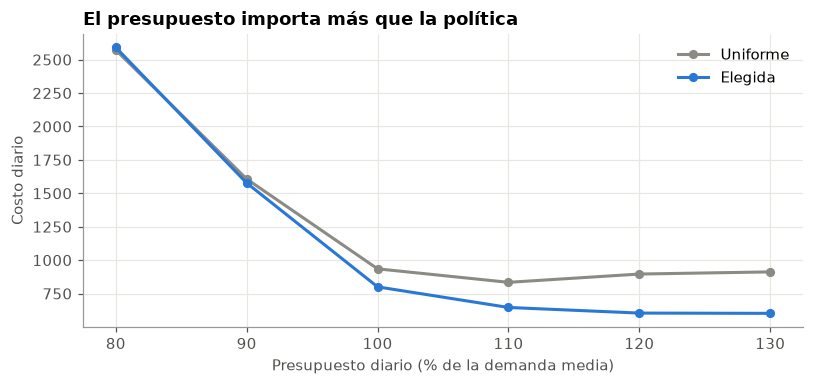

In [8]:
elegida_f, base_opt = POLITICAS[ELEGIDA], p_optimo(V_OPT)
uni = p_uniforme

def tabla_sensibilidad(nombre, casos):
    filas = []
    for etiqueta, cfg in casos:
        r_e, r_u, r_o = simular(elegida_f, FIN_VALID, n, cfg), simular(uni, FIN_VALID, n, cfg), simular(base_opt, FIN_VALID, n, cfg)
        filas.append({nombre: etiqueta, 'Elegida': round(r_e['costo'].mean()), 'Uniforme': round(r_u['costo'].mean()), 'Optimización entera': round(r_o['costo'].mean()),
                      'Ahorro frente a uniforme': pct(1 - r_e['costo'].mean() / r_u['costo'].mean()), 'Servicio de la elegida': resumen(r_e)['Servicio']})
    return pd.DataFrame(filas).set_index(nombre)

media_dem = DEMANDA[:FIN_TRAIN].sum(1).mean()
casos_p = [(pct(p_, 0), replace(BASE, presupuesto=int(round(p_ * media_dem)))) for p_ in [0.8, 0.9, 1.0, 1.1, 1.2, 1.3]]
tb = tabla_sensibilidad('Presupuesto / demanda media', casos_p)
display(tb)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x_ = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3]
for col, color in [('Uniforme', GRIS), ('Elegida', AZUL)]:
    ax.plot(np.array(x_) * 100, tb[col].values, color=color, marker='o', markersize=5, label=col)
ax.set(xlabel='Presupuesto diario (% de la demanda media)', ylabel='Costo diario', title='El presupuesto importa más que la política')
ax.legend()
plt.tight_layout(); plt.show()

### ¿Y si cambian los costos, la capacidad o el reciclaje?

"Depósitos reutilizables" supone que parte de lo depositado queda disponible para retiros al día siguiente, como ocurre en los cajeros recicladores.

In [9]:
display(tabla_sensibilidad('Costo de faltante / costo de saldo', [(f'{f_} / 12', replace(BASE, faltante=f_)) for f_ in [36, 72, 140, 280]]))
display(tabla_sensibilidad('Costo de visita', [(str(v_), replace(BASE, visita=v_)) for v_ in [0, 35, 100, 300]]))
display(tabla_sensibilidad('Capacidad por cajero', [(f'{c_ * BLOQUE:,}', replace(BASE, capacidad=c_)) for c_ in [25, 30, 40, 60]]))
display(tabla_sensibilidad('Depósitos reutilizables', [(pct(r_, 0), replace(BASE, reciclaje=r_)) for r_ in [0.0, 0.5, 1.0]]))

,Elegida,Uniforme,Optimización entera,Ahorro frente a uniforme,Servicio de la elegida
Costo de faltante / costo de saldo,,,,,
36 / 12,535,666,503,19.7 %,97.0 %
72 / 12,627,759,617,17.4 %,97.0 %
140 / 12,800,935,797,14.4 %,97.0 %
280 / 12,1156,1296,1109,10.8 %,97.0 %


,Elegida,Uniforme,Optimización entera,Ahorro frente a uniforme,Servicio de la elegida
Costo de visita,,,,,
0,625,760,622,17.8 %,97.0 %
35,800,935,797,14.4 %,97.0 %
100,1125,1260,1122,10.7 %,97.0 %
300,2125,2260,2139,6.0 %,97.0 %


,Elegida,Uniforme,Optimización entera,Ahorro frente a uniforme,Servicio de la elegida
Capacidad por cajero,,,,,
"25,000",800,966,797,17.2 %,97.0 %
"30,000",800,935,797,14.4 %,97.0 %
"40,000",800,1051,797,23.9 %,97.0 %
"60,000",800,1363,797,41.3 %,97.0 %


,Elegida,Uniforme,Optimización entera,Ahorro frente a uniforme,Servicio de la elegida
Depósitos reutilizables,,,,,
0 %,800,935,797,14.4 %,97.0 %
50 %,604,902,565,33.0 %,99.3 %
100 %,593,918,557,35.4 %,99.4 %


### ¿Cuánto vale tener mejor información?

Simulamos qué pasaría si, al decidir, se conociera la ubicación y el clima de cada cajero.

In [10]:
loc_ = (df.pivot(index='Date', columns='ATM_ID', values='Location')[ATMS].to_numpy() == 'Rural')
clima = df.pivot(index='Date', columns='ATM_ID', values='WeatherImpact')[ATMS].to_numpy()

def esc_info(t, cuantiles=np.linspace(0.025, 0.975, 40)):
    col = []
    for j in range(5):
        previo = (loc_[:t, j] == loc_[t, j]) & (ES_LABORABLE[:t] == ES_LABORABLE[t]) & ((clima[:t, j] > 0) == (clima[t, j] > 0))
        if previo.sum() < 8:
            previo = loc_[:t, j] == loc_[t, j]
        col.append(np.quantile(DEMANDA[:t, j][previo], cuantiles))
    return np.column_stack(col)

r_inf = simular(lambda t, inv, cfg: resolver(inv, esc_info(t), cfg), FIN_VALID, n)
r_el = pru[ELEGIDA]
display(pd.DataFrame({ELEGIDA: resumen(r_el), 'Si se conocieran ubicación y clima del día': resumen(r_inf), 'Información perfecta del periodo': resumen(pru['Información perfecta del periodo'])}).T)

,Costo diario,Servicio,Cajeros-día con quiebre,Saldo al cierre,Visitas por día,Carga diaria
Nivel fijo,800,97.0 %,19.8 %,22349,5.0,82098
Si se conocieran ubicación y clima del día,761,96.6 %,26.7 %,14799,4.99,81533
Información perfecta del periodo,490,98.3 %,3.7 %,9888,4.9,82745


**Lectura.**

- **El presupuesto es la palanca principal.** Pasar de 100 % a 110 % de la demanda media baja el costo de 800 a 646. Con 80 %, todas las políticas se comportan casi igual (cerca de 2,580), porque no hay efectivo para repartir.
- **Por encima de 120 %, más presupuesto casi no ayuda** (604 frente a 602).
- **La conclusión se mantiene con otros costos:** el ahorro frente al uniforme va de 10.8 % a 19.7 % al variar el costo de faltante, y de 6.0 % a 17.8 % al variar el de visita.
- **Más capacidad no ayuda a la política elegida.** Su nivel objetivo ya cabe en 25,000. Sí perjudica al reparto uniforme, que acumula efectivo sin control.
- **Reciclar depósitos tendría mucho valor:** con 50 %, el costo baja a 604.
- **Conocer ubicación y clima solo ahorraría 4.9 %** (761), incluso con un pronóstico bastante mejor. Una mejora en el pronóstico no se traduce por completo en ahorro.

## 8. Ficha de la política

Resume qué se recomienda y cómo se comportó.

In [11]:
ficha = {
    'Política': ELEGIDA,
    'Periodo de prueba': f'{pd.Timestamp(DIAS[FIN_VALID]).date()} a {pd.Timestamp(DIAS[-1]).date()}',
    'Costo diario simulado': f"{pru[ELEGIDA]['costo'].mean():,.0f}",
    'Costo del reparto uniforme': f"{pru['Reparto uniforme']['costo'].mean():,.0f}",
    'Servicio': resumen(pru[ELEGIDA])['Servicio'],
    'Cajeros-día con quiebre': resumen(pru[ELEGIDA])['Cajeros-día con quiebre'],
    'Presupuesto diario': f'{PRESUPUESTO * BLOQUE:,}',
    'Nivel objetivo por cajero': ', '.join(f'{a_}: {int(np.ceil(v_)) * BLOQUE:,}' for a_, v_ in zip(ATMS, np.quantile(DEMANDA[:FIN_TRAIN], tau, axis=0))),
}
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame({'Valor': ficha}))

,Valor
Política,Nivel fijo
Periodo de prueba,2023-10-01 a 2023-12-31
Costo diario simulado,800
Costo del reparto uniforme,935
Servicio,97.0 %
Cajeros-día con quiebre,19.8 %
Presupuesto diario,"85,000"
Nivel objetivo por cajero,"ATM_1: 23,000, ATM_2: 23,000, ATM_3: 24,000, ATM_4: 23,000, ATM_5: 23,000"


## 9. Limitaciones y monitoreo

**Limitaciones**

- **Datos sintéticos.** Los resultados no representan a un banco real.
- **Costos, capacidad y saldo inicial supuestos.**
- **Demanda completa.** Se asume que los retiros registrados incluyen toda la demanda.
- **Sin rutas ni tiempos.** Cada cajero se puede abastecer cada mañana, sin restricciones de camión.
- **Un solo año y solo 3 feriados.**
- **Decisión de un día.** La optimización no mira varios días hacia adelante.
- **Diseño no totalmente ciego.** La referencia de información perfecta se agregó después de ver la prueba, y no influyó en la elección.

**Antes de usarlo en un banco** se necesitarían saldos reales, registros de quiebre, capacidades, costos, ventanas de abastecimiento y denominaciones.

**Plan de monitoreo propuesto**

| Indicador | Frecuencia | Verde | Revisar | Actuar |
|---|---|---|---|---|
| Servicio | Semanal | ≥ 97 % | 94 % a 97 % | < 94 % |
| Cajeros-día con quiebre | Semanal | ≤ 20 % | 20 % a 30 % | > 30 % |
| Demanda media frente al entrenamiento | Mensual | ±5 % | ±5 % a ±15 % | Más de ±15 % |
| Costo frente a reparto uniforme | Mensual | Menor | Igual | Mayor |

Son una propuesta inicial, y deben ajustarse con datos reales.

## Conclusión

**Recomendación.** Reponer cada cajero hasta un nivel objetivo fijo, calculado como el cuantil 92.1 de sus retiros históricos. Los niveles están en la ficha de la sección 8.

**Por qué**

| Política | Costo diario en prueba | Servicio |
|---|---|---|
| **Nivel fijo (elegida)** | **800** | 97.0 % |
| Optimización entera | 797 | 96.8 % |
| Nivel por tipo de día | 824 | 96.6 % |
| Reparto uniforme | 935 | 97.0 % |
| Información perfecta (referencia) | 490 | 98.3 % |

**Las ideas para llevarse**

1. Antes de optimizar, comprueba si hay algo que se pueda predecir.
2. Más sofisticación no sirve cuando la información es poca: el nivel fijo empató con el optimizador.
3. Usar pocos datos recientes puede empeorar una decisión, porque se persigue ruido.
4. Un dato muy predictivo no sirve si no existe al decidir.
5. Cuando el presupuesto es escaso, ningún algoritmo lo compensa: la mayor mejora viene de ajustar los recursos.

## Ejercicios

1. **Cambia `PRESUPUESTO_PCT` a 0.9.** ¿Sigue siendo mejor el nivel fijo?
2. **Cambia `COSTO_FALTANTE` a 300.** ¿Cuál sería la nueva razón crítica? ¿Debería cambiar el nivel objetivo?
3. **Cambia `TOLERANCIA_COSTO` a 0.** ¿Qué política se elige?
4. **Prueba `CAPACIDAD = 20`.** ¿Qué ocurre con el servicio?
5. **Agrega `Location` como variable conocida.** ¿Por qué mejora tanto el error, y por qué sería una trampa?
6. **Para pensar:** si cada cajero tuviera un nivel mínimo de servicio obligatorio, ¿cómo cambiarías la función objetivo?